# 05 · Biological interpretation
Model-based rankings, differential expression and pathway enrichment, read together. These are associations
with tissue type in one cohort, not causal claims.

In [1]:
import json, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore", category=FutureWarning)
from oncogene.config import Paths, load_config
from oncogene.data.load import load_processed
paths, cfg = Paths(), load_config()
ds = load_processed(paths)
X, meta, ann = ds.X, ds.meta, ds.annotation
M = paths.metrics
print(X.shape, meta.shape)

(50, 17868) (50, 9)


In [2]:
r = pd.read_csv(M/'gene_ranking.csv', dtype={'probe_id': str})
for m, g in r.groupby('method'):
    print(f"{m}:\n  ", ', '.join(g.nsmallest(12, 'rank_within_method')['gene_symbol'].fillna('?')))

LR standardized coefficient (final model):
   INHBA, C2ORF40, DMD, OLR1, SYN2, FIGF, SULF1, MME, SPRY2, PPAP2B, TMEM220, NR3C2
Outer-fold selection frequency (logistic_regression):
   C2ORF40, TFPI, SDPR, CHL1, IGSF10, LDB2, ADH1B, ADH1C, MEOX2, INHBA, MAMDC2, LYVE1
Outer-fold selection frequency (random_forest):
   LEPR, RAG1AP1, DTL, PPAP2B, TGFBR3, JTB, ANGPTL1, CD34, C2ORF40, TFPI, SDPR, PID1
Outer-fold selection frequency (svm):
   C2ORF40, TFPI, SDPR, CHL1, IGSF10, LDB2, ADH1B, ADH1C, MEOX2, INHBA, MAMDC2, LYVE1
Permutation importance, held-out margin drop (logistic_regression):
   C2ORF40, INHBA, DMD, FIGF, SPRY2, TMEM220, FXYD1, TFPI, MAMDC2, MEOX2, ADAMTS5, ABCA10
Permutation importance, held-out margin drop (random_forest):
   DMD, ADAMTS5, FAT4, PARK2, FAM13C, INHBA, AKAP12, TFPI, IGSF10, ADH1C, CAV1, FIGF
Permutation importance, held-out margin drop (svm):
   INHBA, C2ORF40, PPAP2B, MAMDC2, SPRY2, SYN2, DMD, TMEM220, ADAMTS5, CHL1, MEOX2, NR3C2
RF impurity importance (final

In [3]:
lr = r[r.method.str.startswith('LR standardized')].head(30)
lr[['gene_symbol','signed_value','log2_fold_change','p_adj']]

,gene_symbol,signed_value,log2_fold_change,p_adj
0,INHBA,0.055625,2.4384,1.174730e-10
1,C2ORF40,-0.054729,-2.0860,1.536556e-09
2,DMD,-0.052161,-2.6860,2.162499e-13
3,OLR1,0.051878,2.7464,1.645016e-10
4,SYN2,-0.051697,-0.9036,3.800062e-10
5,FIGF,-0.050802,-4.1400,1.385482e-12
6,SULF1,0.050491,1.8000,1.325566e-08
7,MME,-0.050397,-2.6796,1.907816e-10
8,SPRY2,-0.050158,-2.1232,1.907816e-10
9,PPAP2B,-0.049846,-1.4036,1.378285e-10


In [4]:
pw = pd.read_csv(M/'pathway_results.csv')
pw.groupby(['library','direction']).head(5)[['library','direction','term_name','overlap','p_adj']]

,library,direction,term_name,overlap,p_adj
0,Reactome_2022,up in tumor,"Cell Cycle, Mitotic",54,2.046798e-23
1,Reactome_2022,up in tumor,Cell Cycle Checkpoints,37,5.046650e-20
2,Reactome_2022,up in tumor,Resolution Of Sister Chromatid Cohesion,23,6.334506e-16
3,Reactome_2022,up in tumor,Mitotic Prometaphase,27,2.402741e-14
4,Reactome_2022,up in tumor,Mitotic Anaphase,28,2.124700e-13
1376,Reactome_2022,down in tumor,Signaling By Nuclear Receptors,22,1.265116e-04
1377,Reactome_2022,down in tumor,Ethanol Oxidation,5,3.124804e-03
1378,Reactome_2022,down in tumor,Extracellular Matrix Organization,21,3.124804e-03
1379,Reactome_2022,down in tumor,Transcriptional Regulation Of White Adipocyte ...,11,3.124804e-03
1380,Reactome_2022,down in tumor,Signaling By Receptor Tyrosine Kinases,30,3.124804e-03


## Composition check
Adipocyte vs. proliferation marker scores (fixed literature panels) separate the tissues on their own.

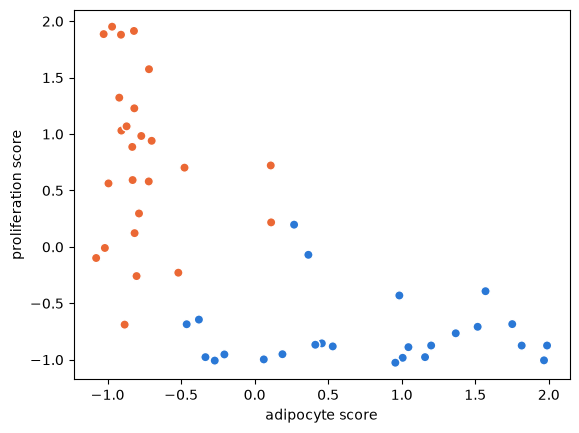

In [5]:
ms = pd.read_csv(M/'marker_scores.csv', index_col=0)
c = ms.tissue_type.map({'Adjacent normal':'#2a78d6','Tumor':'#eb6834'})
plt.scatter(ms.adipocyte_score, ms.proliferation_score, c=c, s=45, edgecolor='white')
plt.xlabel('adipocyte score'); plt.ylabel('proliferation score');

In [6]:
from sklearn.metrics import roc_auc_score
for col in ['adipocyte_score','proliferation_score']:
    print(col, 'AUC (descriptive, no CV needed: fixed panel)', round(roc_auc_score(ms.tissue_type=='Tumor', ms[col]), 3))

adipocyte_score AUC (descriptive, no CV needed: fixed panel) 0.019
proliferation_score AUC (descriptive, no CV needed: fixed panel) 0.976
